# <span style="color:green"> Numerical Simulation Laboratory (NSL) </span>
## <span style="color:blue">  Numerical exercises 9</span>

# Overview of Genetic Algorithms

It should be noted that both mutations and crossovers destroy solutions, among which the best possible one might also appear.

The functioning of the algorithm can be outlined as follows:

1. A population of $n$ chromosomes, each consisting of $l$ genes, is initialized, representing candidate solutions to the problem to be optimized;
2. A fitness function is defined and calculated for each chromosome in the population;
3. A new population of $n$ elements is created by applying methods that simulate natural selection:
    - Two individuals are selected from the current population. The selection algorithm must be designed to favor the choice of the best individuals, meaning the probability of selection must increase with the fitness function;
    - Crossover occurs with a probability $P_c$ and leads to the creation of two offspring chromosomes. If it does not occur, the offspring are exact copies of the two parents;
    - Mutations are applied to the offspring with a probability $P_m$;
5. The offspring are inserted into the new population;
6. The steps are iterated until a new population is generated that replaces the previous one.

Each execution of the evolutionary process defines a **generation**, at the end of which multiple high-fitness chromosomes will appear in the population.

# Exercise 09.1

## Result

In this exercise, a Genetic Algorithm  was implemented to solve the Traveling Salesman Problem (TSP) for $N = 34$ cities. Both a constrained geometry (a circle) and an unconstrained geometry (a square) were considered, minimizing the cost function $L^{(1)}$.


#### 1. Code Architecture 
The codebase is structured into:
* **`City` (`city.h`)**: Manages individual cities by storing their Cartesian coordinates $(x, y)$ and an identifying index (`id`). It implements methods for calculating Euclidean distance and squared distance $L^{(1)}$, as well as saving geographical positions to a file.
* **`Individual` (`individual.h`)**: Represents a single path (genotype) via a 1D vector of integers . It handles:
  * Random initialization using the Fisher-Yates algorithm (keeping the first city $0$ fixed to eliminate mirror degeneracy).
  * Strict constraint validation via a dedicated `Check()` function (each city visited once and only once, returning to the starting point.
  * Fitness evaluation ($f = 1/L$) and management of the four genetic mutation operators.
* **`Population` (`population.h`)**: Manages the entire population of individuals, implementing:
  * Performance-based sorting (by $L$).
  * Elitism: automatic preservation of the best individual from the previous generation (`individuals[0]`).
  *  Selection.
  * The main evolutionary cycle (`Evolve`), coordinating crossover and independent mutations.


#### 2. Genetic Operators and Algorithmic Choices

* **Selection (`SelectParent`)**: Adopts a strategy based on position within the sorted population via the law $j = \text{int}(M \cdot r^p) + 1$ (with $p > 1$), rewarding better paths without completely discarding population diversity.
* **Crossover Operator**: Implemented with a shared cut point ($1 \le \text{cut} \le N-2$). Offspring inherit the first part of the path from the first parent and complete the sequence using the second parent's cities in the order they appear, thus preserving constraint validity.
* **Mutation Operators**: Four distinct mutations are applied with independent probabilities ($p_m < 10\%$):
  1. *Pair swap of two cities* (`swamp_two`).
  2. *Shift of $n$ positions for $m$ contiguous cities* (`shift_n`).
  3. *Block permutation* between groups of contiguous cities (`swamp_block`).
  4. *Order inversion* of a block of cities (`Inversion`).


#### 3. Configurations and Geometries Tested
The algorithm was executed for $N = 34$ cities across two different scenarios:
1. **Circle**: 34 cities randomly placed on the perimeter of a unit circle ($x = \cos\theta, y = \sin\theta$).
2. **Square**: 34 cities uniformly distributed inside a 2D square $[0,0.5] \times [0,0.5]$.

The log files generated by the C++ simulation (`loss_circle.dat`, `loss_square.dat`, `best_path_circle.dat`, `best_path_square.dat`) are read and processed in this notebook to track loss convergence ($L_{\text{best}}$ and $\langle L \rangle$ averaged over the best half of the population) and visually display the optimal paths found.

#### 4. Parameters
The population has $M = 300$ individuals, the crossover probability is $P_c = 0.8$ and each of the four mutations is applied with probability $p_m = 0.09$. The algorithm runs for 1000 generations.

---

**Exercise**

Write a code to solve the TSP with a **Genetic** algorithm (GA). Note that you should invent **some** *genetic-mutation* operators and a *genetic-crossover* operator which should preserve the bonds of the problem: the salesman must visit one and only one time every city and must be back to the first city in the end of the path.

Once the data structure of your code is ready, before you start coding your genetic operators, I warmly suggest you to code the creation of the starting population and to code a **check function** that verifies if every *individual* fulfils the bonds. Then check your starting population ... and use your check function every time you create a new individual.

You have to invent also a **selection** operator. 
The fitness and thus the order of the population should be obtained from $L^{(2)}(\vec{x}_1, \vec{x}_2, \dots, \vec{x}_N)$ or $L^{(1)}(\vec{x}_1, \vec{x}_2, \dots, \vec{x}_N)$. Once your starting population has been ordered on a fitness basis,
you have 2 possibilities:
1. write a selection operator which obtain the probability to select an individual from $L^{(2)}(\vec{x}_1, \vec{x}_2, \dots, \vec{x}_N)$ or $L^{(1)}(\vec{x}_1, \vec{x}_2, \dots, \vec{x}_N)$
2. write a selection operator which simply uses the order in the orderd population with $M$ individuals, e.g. select the individual $j$ with the algorithm: $j= int(M \times r^p)+1$ where $r$ is a uniform random number $r\in[0,1)$ and $p$ a convenient exponent. 

<span style="color:red">Set the first city to always appear at position 1, so as to reduce the degeneration of the shortest route to be 2, which corresponds to walking the shortest route in clockwise and anti-clockwise directions.</span>

Then you can start introducing some *genetic-mutation* operators, for example:
1. pair permutation of cities (except for the first city), e.g. $\left[ 1, 2, 3, 4, 5 \right] \to \left[ 1, 2, 4, 3, 5 \right]$ (At this point you should already have such operator ... how have you generated the starting population?).
2. shift of $+n$ positions for $m$ contiguous cities (except for the first city and $m \lt N-1$), e.g. $\left[ 1, 2, 3, 4, 5 \right] \to \left[ 1, 4, 5, 2, 3 \right] $ for a $+2$ shift of the second and third cities.
3. permutation among $m$ contiguous cities (except for the first city) with other (different!) $m$ contiguous cities ($m<N/2$), e.g. $\left[ 1, 2, 3, 4, 5 \right] \to \left[ 1, 4, 5, 2, 3 \right] $ for a permutation of the second and third cities with the last 2.
4. inversion of the order in which they appear in the path of $m$ cities (except for the first city and $m \le N$), e.g. $\left[ 1, 2, 3, 4, 5 \right] \to \left[ 1, 4, 3, 2, 5 \right]$ for the inversion of the cities from 2 to 4.

Every mutation will have its probability, $p^{(i)}_m$ to be called and typically $p^{(i)}_m < 10\%$, but before to include crossover you can check if the GA is able to perform a good *random search* using only mutation operators (in this case $p^{(i)}$ could be higher than in the previous suggestion).

At this point you can add a *crossover* operator (that fulfils the bonds and that you will call with probability $p^{(i)}_c > 50\%$):

given a selected mother and father, e.g. 
$$
\left[ 1, 2, 3, 4, 5 \right]\\
\left[ 1, 5, 4, 3, 2 \right] 
$$
1. cut their paths at the same position:
$$
\left[ 1, 2, 3 | 4, 5 \right]\\
\left[ 1, 5, 4 | 3, 2 \right] 
$$
2. conserve the first part of the paths:
$$
\left[ 1, 2, 3 | X, Y \right]\\
\left[ 1, 5, 4 | X, Y \right] 
$$
3. complete the paths with the missing cities adding them in the **order** in which they appear in the consort:
$$
\left[ 1, 2, 3 | 5, 4 \right]\\
\left[ 1, 5, 4 | 2, 3 \right] 
$$

Here you are: you have two sons that you can add to the new generation ... and so on!

Apply your code to the optimization of a path among 

- <span style="color:blue">34 cities randomly placed **on** a circumference</span>
- <span style="color:blue">34 cities randomly placed **inside** a square</span>

Show your results via:

- <span style="color:red">a picture of $L^{(2)}$ (or $L^{(1)}$) of the best path and of $\langle L^{(2)}\rangle$ (or $\langle L^{(1)}\rangle$), averaged on the best half of the population, as a function of the iterations/generations of your algorithm</span>
- <span style="color:red">a picture of the best path in cartesian coordinates</span>

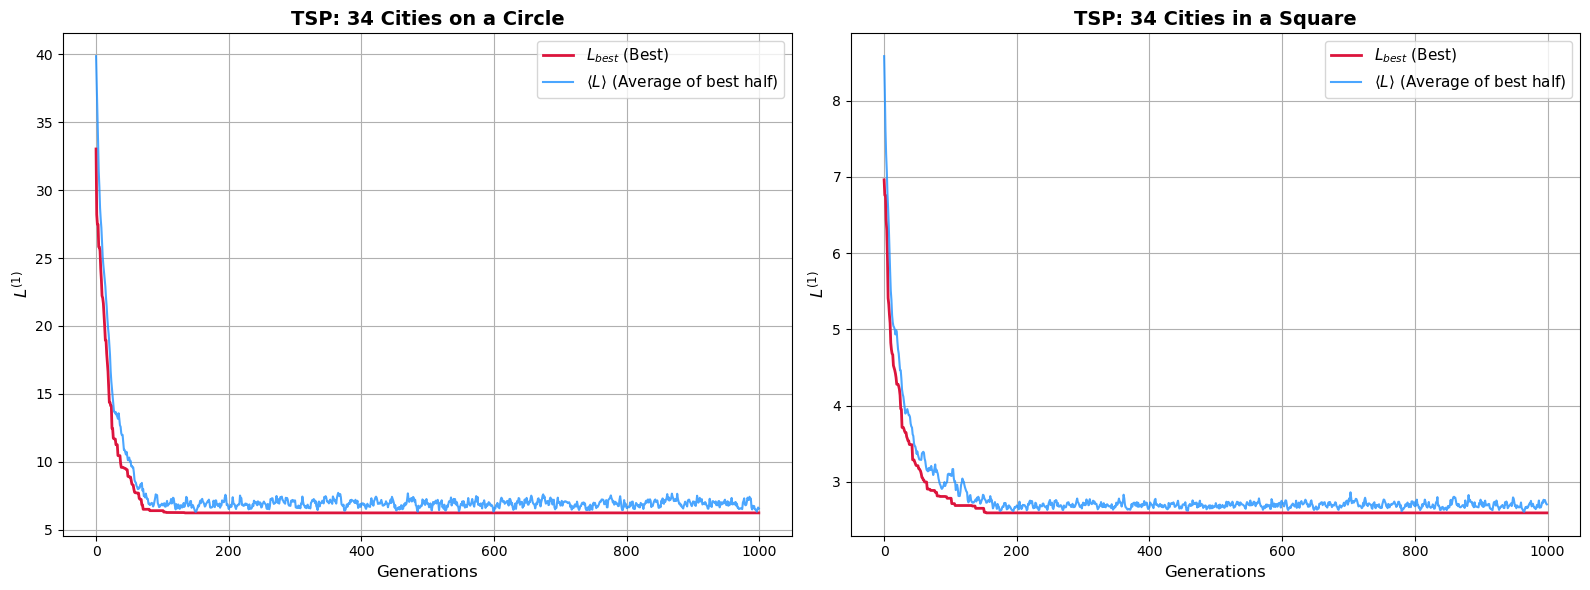

In [6]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Caricamento dati Circonferenza
gen_c, l_best_c, l_mean_c = np.loadtxt("loss_circle.dat", unpack=True)

# 2. Caricamento dati Quadrato
gen_s, l_best_s, l_mean_s = np.loadtxt("loss_square.dat", unpack=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Circle Plot
axes[0].plot(gen_c, l_best_c, label=r'$L_{best}$ (Best)', color='crimson', linewidth=2)
axes[0].plot(gen_c, l_mean_c, label=r'$\langle L \rangle$ (Average of best half)', color='dodgerblue', alpha=0.8, linewidth=1.5)
axes[0].set_title('TSP: 34 Cities on a Circle', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Generations', fontsize=12)
axes[0].set_ylabel(r'$L^{(1)}$', fontsize=12)
axes[0].legend(fontsize=11)
axes[0].grid(True)

# Square Plot
axes[1].plot(gen_s, l_best_s, label=r'$L_{best}$ (Best)', color='crimson', linewidth=2)
axes[1].plot(gen_s, l_mean_s, label=r'$\langle L \rangle$ (Average of best half)', color='dodgerblue', alpha=0.8, linewidth=1.5)
axes[1].set_title('TSP: 34 Cities in a Square', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Generations', fontsize=12)
axes[1].set_ylabel(r'$L^{(1)}$', fontsize=12)
axes[1].legend(fontsize=11)
axes[1].grid(True)
plt.tight_layout()
plt.show()

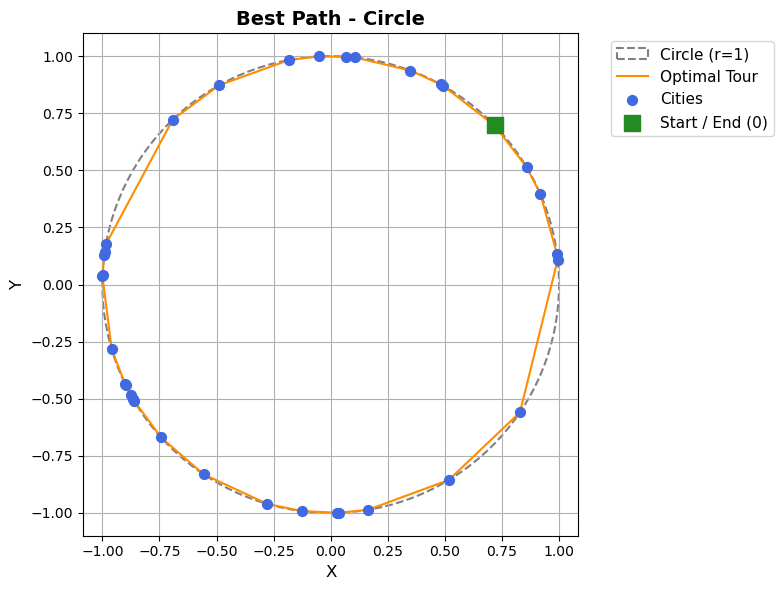

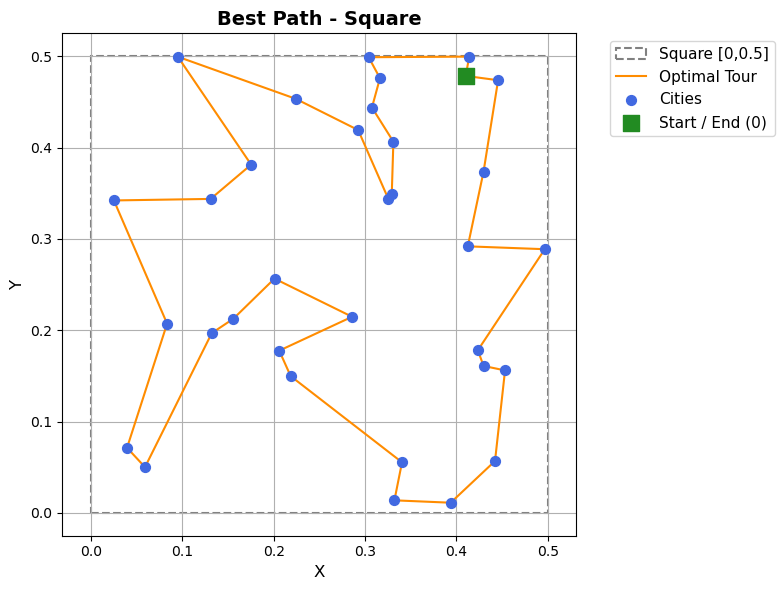

In [10]:
def plot_best_path(cities_file, path_file, title, shape_type="circle"):
    c_id, cx, cy = np.loadtxt(cities_file, skiprows=1, unpack=True)
    p_id, px, py = np.loadtxt(path_file, unpack=True)
    
    plt.figure(figsize=(8, 6))
    
# If circle, draw the geometric circle of radius 1
    if shape_type == "circle":
        circle = plt.Circle((0, 0), 1.0, color='gray', fill=False, linestyle='--', linewidth=1.5, label='Circle (r=1)')
        plt.gca().add_patch(circle)
    elif shape_type == "square":
        # If square, draw the perimeter of the square [0,1]x[0,1] (adjusted label/dimensions as in original code)
        square = plt.Rectangle((0, 0), 0.5, 0.5, color='gray', fill=False, linestyle='--', linewidth=1.5, label='Square [0,0.5]')
        plt.gca().add_patch(square)
        
    # Plot the path and the cities
    plt.plot(px, py, color='darkorange', linestyle='-', linewidth=1.5, zorder=2, label='Optimal Tour')
    plt.scatter(cx, cy, color='royalblue', s=50, zorder=3, label='Cities')
    plt.scatter(px[0], py[0], color='forestgreen', s=120, zorder=4, marker='s', label='Start / End (0)') 
    plt.title(title, fontsize=14, fontweight='bold')
    plt.xlabel('X', fontsize=12)
    plt.ylabel('Y', fontsize=12)
    
    # Sposta la legenda all'esterno a destra per non coprire i punti
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=11)
    plt.grid(True)
    plt.axis('equal')
    plt.tight_layout()
    plt.show()

# Execution for the Circle
plot_best_path("cities_circle.dat", "best_path_circle.dat", "Best Path - Circle", shape_type="circle")

# Execution for the Square
plot_best_path("cities_square.dat", "best_path_square.dat", "Best Path - Square", shape_type="square")

In [12]:
# Calcolo e stampa dei valori migliori di L
min_l_circle = np.min(l_best_c)
final_l_circle = l_best_c[-1]

min_l_square = np.min(l_best_s)
final_l_square = l_best_s[-1]
print("==========================================")
print("       TSP OPTIMIZATION RESULTS          ")
print("==========================================")
print("1. CIRCLE:")
print(f"   - Minimum historical L_best: {min_l_circle:.5f}")
print(f"   - Final L_best (last gen): {final_l_circle:.5f}\n")
print("2. SQUARE:")
print(f"   - Minimum historical L_best: {min_l_square:.5f}")
print(f"   - Final L_best (last gen): {final_l_square:.5f}")
print("==========================================")

       TSP OPTIMIZATION RESULTS          
1. CIRCLE:
   - Minimum historical L_best: 6.24306
   - Final L_best (last gen): 6.24306

2. SQUARE:
   - Minimum historical L_best: 2.59377
   - Final L_best (last gen): 2.59377


# Bonus

Analyses the Genetic Algorithm performance for the unit circle TSP, comparing the optimised tour length against the analytical circumference ($2.0 \times \pi$).

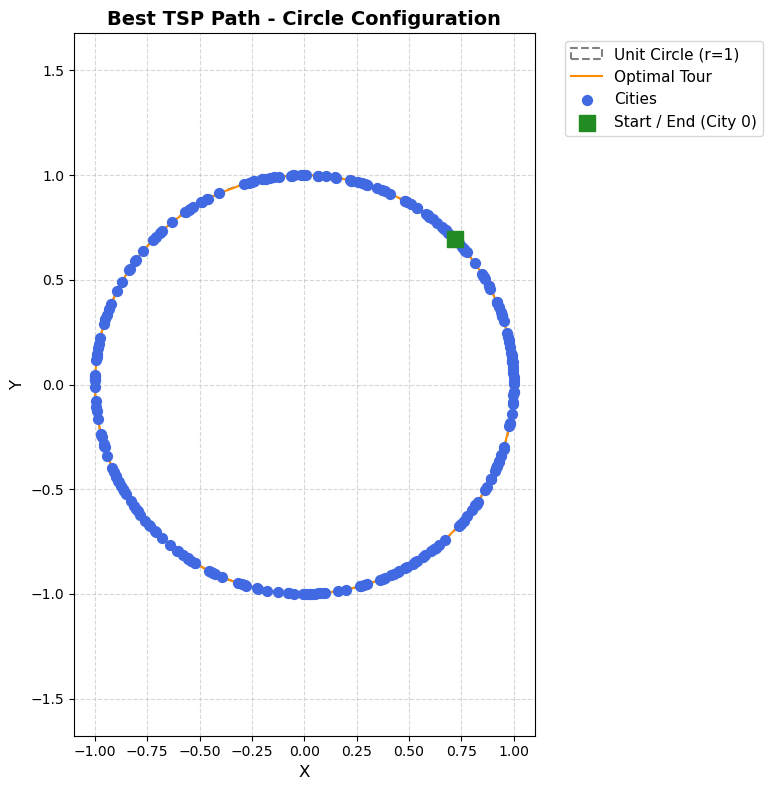

In [24]:
import matplotlib.pyplot as plt
import numpy as np

def plot_best_path(cities_file, path_file, title):
    # Load cities and optimal path files
    c_id, cx, cy = np.loadtxt(cities_file, skiprows=1, unpack=True)
    p_id, px, py = np.loadtxt(path_file, unpack=True)
    
    plt.figure(figsize=(8, 8))
    
    # Draw the geometric unit circle (radius = 1)
    circle = plt.Circle((0, 0), 1.0, color='gray', fill=False, linestyle='--', linewidth=1.5, label='Unit Circle (r=1)')
    plt.gca().add_patch(circle)
        
    # Plot the optimal tour path and cities
    plt.plot(px, py, color='darkorange', linestyle='-', linewidth=1.5, zorder=2, label='Optimal Tour')
    plt.scatter(cx, cy, color='royalblue', s=50, zorder=3, label='Cities')
    plt.scatter(px[0], py[0], color='forestgreen', s=120, zorder=4, marker='s', label='Start / End (City 0)')
    
    plt.title(title, fontsize=14, fontweight='bold')
    plt.xlabel('X', fontsize=12)
    plt.ylabel('Y', fontsize=12)
    
    # Move legend outside to the right
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=11)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.axis('equal')
    plt.tight_layout()
    plt.show()

# Execution for the Circle TSP
plot_best_path("cities_circle2.dat", "best_path_circle2.dat", "Best TSP Path - Circle Configuration")

In [37]:
# Calculation and printing of best L values
min_l_circle = np.min(l_best_c)
final_l_circle = l_best_c[-1]
theoretical_length = 2 * np.pi  # For a unit circle (r = 1)

print("==========================================")
print("         TSP OPTIMIZATION RESULTS         ")
print("==========================================")
print("1. CIRCLE CONFIGURATION:")
print(f"   - Theoretical circle length : {theoretical_length:.5f}")
print(f"   - Final L_best (last gen)   : {final_l_circle:.5f}\n")

         TSP OPTIMIZATION RESULTS         
1. CIRCLE CONFIGURATION:
   - Theoretical circle length : 6.28319
   - Final L_best (last gen)   : 6.24306

